In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import sklearn

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

print("All Libraries Imported Successfully!")

TensorFlow: 2.21.0
NumPy: 2.5.1
Pandas: 2.2.3
OpenCV: 4.13.0
All Libraries Imported Successfully!


In [2]:
import os

print("Current Directory:", os.getcwd())
print("Project Files:", os.listdir())

Current Directory: C:\Users\Rohit singh\Desktop\nareshIt\project\Deep-learning\Plant-Disease-Detection
Project Files: ['.git', '.gitignore', '.ipynb_checkpoints', 'PlantVillage', 'Plant_Disease_Detection.ipynb', 'venv']


In [3]:
!git init

Reinitialized existing Git repository in C:/Users/Rohit singh/Desktop/nareshIt/project/Deep-learning/Plant-Disease-Detection/.git/


# Import Libraries

In [7]:
# Import Operating System Library
import os

# Import Numerical and Data Analysis Libraries
import numpy as np
import pandas as pd

# Import Data Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import Image Processing Library
import cv2

# Import Image Handling Library
from PIL import Image

# Import Random Module
import random

# Display successful import message
print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [8]:

# Define the dataset directory
path = os.path.join(os.getcwd(), "PlantVillage")

# Check whether dataset directory exists
if os.path.exists(path):
    print("Dataset Found Successfully!")
else:
    print("Dataset Directory Not Found!")

# Display dataset path
print("Dataset Path:", path)


Dataset Found Successfully!
Dataset Path: C:\Users\Rohit singh\Desktop\nareshIt\project\Deep-learning\Plant-Disease-Detection\PlantVillage


**Step 3: Explore Dataset Directories**
- Purpose: Display all folders available inside the PlantVillage dataset.

In [10]:
# Get all items from dataset directory
dataset_items = os.listdir(path)

# Display all dataset folders
print("Dataset Directories:\n")

for item in dataset_items:
    
    item_path = os.path.join(path, item)
    
    if os.path.isdir(item_path):
        print(item)


Dataset Directories:

Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___healthy
Potato___Late_blight
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_healthy
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_mosaic_virus
Tomato__Tomato_YellowLeaf__Curl_Virus


**Step 4: Identify Disease Classes**
- Purpose: Identify all unique plant disease classes available in the dataset.

In [12]:
# Get all class folders
classes = [
    folder for folder in os.listdir(path)
    if os.path.isdir(os.path.join(path, folder))
]

# Display total number of classes
print("Total Disease Classes:", len(classes))

# Display all disease classes
print("\nDisease Classes:\n")

for index, class_name in enumerate(classes, start=1):
    print(f"{index}. {class_name}")


Total Disease Classes: 15

Disease Classes:

1. Pepper__bell___Bacterial_spot
2. Pepper__bell___healthy
3. Potato___Early_blight
4. Potato___healthy
5. Potato___Late_blight
6. Tomato_Bacterial_spot
7. Tomato_Early_blight
8. Tomato_healthy
9. Tomato_Late_blight
10. Tomato_Leaf_Mold
11. Tomato_Septoria_leaf_spot
12. Tomato_Spider_mites_Two_spotted_spider_mite
13. Tomato__Target_Spot
14. Tomato__Tomato_mosaic_virus
15. Tomato__Tomato_YellowLeaf__Curl_Virus


**Step 5: CountImages in Each Class**
- Purpose: Calculate the number of images available in each disease class.

In [14]:
# Define supported image formats
image_extensions = (".jpg", ".jpeg", ".png")

# Create an empty dictionary
class_counts = {}

# Count images in every class
for class_name in classes:

    # Get class folder path
    folder_path = os.path.join(path, class_name)

    # Get all image files
    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(image_extensions)
    ]

    # Store image count
    class_counts[class_name] = len(images)

# Convert dictionary into DataFrame
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Disease Class", "Image Count"]
)

# Display dataset summary
print(df.to_string(index=False))


                              Disease Class  Image Count
              Pepper__bell___Bacterial_spot          997
                     Pepper__bell___healthy         1478
                      Potato___Early_blight         1000
                           Potato___healthy          152
                       Potato___Late_blight         1000
                      Tomato_Bacterial_spot         2127
                        Tomato_Early_blight         1000
                             Tomato_healthy         1591
                         Tomato_Late_blight         1909
                           Tomato_Leaf_Mold          952
                  Tomato_Septoria_leaf_spot         1771
Tomato_Spider_mites_Two_spotted_spider_mite         1676
                        Tomato__Target_Spot         1404
                Tomato__Tomato_mosaic_virus          373
      Tomato__Tomato_YellowLeaf__Curl_Virus         3208


**Step 6: Calculate Total Dataset Images**
- Purpose: Calculate total images, total classes and average images per class.

In [17]:
# Calculate total number of images
total_images = df["Image Count"].sum()

# Calculate total number of classes
total_classes = len(classes)

# Calculate average images per class
average_images = df["Image Count"].mean()

# Display dataset statistics
print("Total Classes:", total_classes)
print("Total Images:", total_images)
print("Average Images Per Class:", round(average_images, 2))


Total Classes: 15
Total Images: 20638
Average Images Per Class: 1375.87


**Step 7: Check Missing or Empty Classes**
- Purpose: Identify classes that do not contain any images.

In [18]:
# Find classes with zero images
empty_classes = df[df["Image Count"] == 0]

# Display empty classes
print("Empty Classes:")

if empty_classes.empty:
    print("No Empty Classes Found!")
else:
    print(empty_classes)


Empty Classes:
No Empty Classes Found!


**Step 8: Analyze Class Distribution**
- Purpose: Visualize the number of images available in each disease class and identify class imbalance.

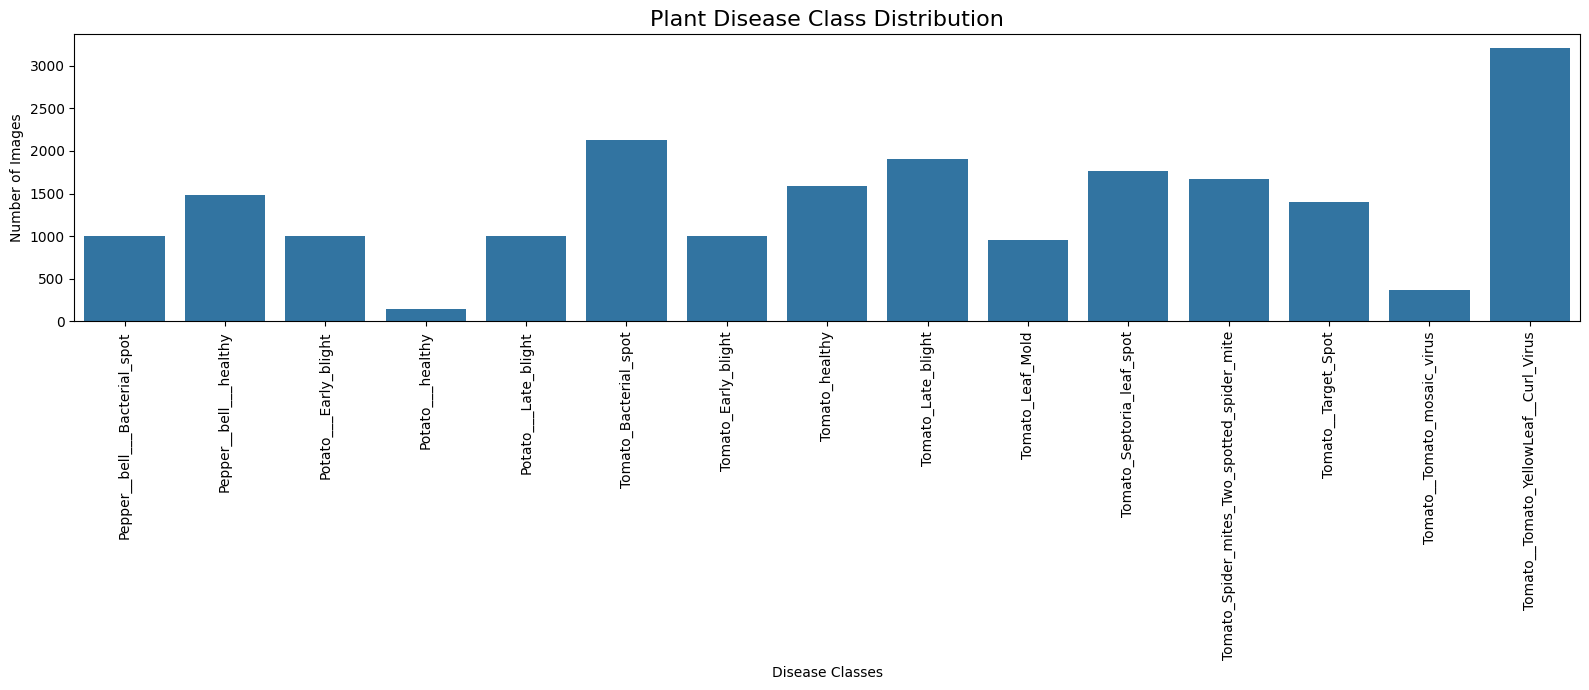

In [19]:

# Set figure size
plt.figure(figsize=(16, 7))

# Create class distribution bar chart
sns.barplot(
    data=df,
    x="Disease Class",
    y="Image Count"
)

# Add chart title and labels
plt.title("Plant Disease Class Distribution", fontsize=16)
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")

# Rotate class names
plt.xticks(rotation=90)

# Adjust chart layout
plt.tight_layout()

# Display chart
plt.show()
